# Evaluation results analysis

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RUN_ID = "r1"      # predictions_<RUN_ID>.jsonl
HORIZON = "1M"
K = 1              # labels_<HORIZON>_k<K>.jsonl
CLASSES = ["BUY", "HOLD", "SELL"]

pd.options.display.float_format = "{:.3f}".format


def find_eval_dir():
    for p in (Path("../datalake/evaluation"), Path("../../datalake/evaluation"), Path("datalake/evaluation")):
        if p.is_dir():
            return p
    raise FileNotFoundError("datalake/evaluation not found (run the notebook from repo_kodowe/notebooks)")


EVAL_DIR = find_eval_dir()
print("folder:", EVAL_DIR.resolve())

folder: C:\Users\Admin\Inzynierka\datalake\evaluation


## 1. Data

From the predictions file we keep only the rows with a `direction` (successful
debates) and, if a sample `(ticker, as_of, horizon)` appears more than once, its last
row. Then they are joined with the labels on the same key.

In [2]:
def read_jsonl(path):
    rows = []
    for line in path.read_text(encoding="utf-8", errors="replace").splitlines():
        if not line.strip(chr(0) + " "):  # blank line or zero padding from an interrupted write
            continue
        try:
            rows.append(json.loads(line))
        except json.JSONDecodeError:
            pass
    return rows


KEY = ["ticker", "as_of", "horizon"]
labels = pd.DataFrame(read_jsonl(EVAL_DIR / f"labels_{HORIZON}_k{K}.jsonl"))
preds = pd.DataFrame(read_jsonl(EVAL_DIR / f"predictions_{RUN_ID}.jsonl"))

preds = preds[preds["direction"].notna()].drop_duplicates(KEY, keep="last")
df = preds.merge(labels, on=KEY, how="inner", suffixes=("", "_label"))

df["as_of"] = pd.to_datetime(df["as_of"])
df["quarter"] = df["as_of"].dt.to_period("Q").astype(str)
df["correct"] = df["direction"] == df["label"]

print(f"labels: {len(labels)}   successful predictions: {len(preds)}   joined: {len(df)}")
print(f"labels without a prediction: {len(labels) - len(df)}")
df.head()

labels: 190   successful predictions: 190   joined: 190
labels without a prediction: 0


,ticker,as_of,horizon,direction,confidence,rounds_used,critic_agreed,error,p0,sigma_h,upper,lower,label,touch_date,ret_end,k,span,quarter,correct
0,AAPL,2025-02-01,1M,HOLD,0.600,1,True,None,234.300,0.068,250.221,218.379,HOLD,None,0.001,1.000,100,2025Q1,True
1,AAPL,2025-03-01,1M,BUY,0.825,3,True,None,240.362,0.069,257.031,223.693,SELL,2025-03-11,-0.082,1.000,100,2025Q1,False
2,AAPL,2025-04-01,1M,HOLD,0.700,1,True,None,221.826,0.075,238.564,205.087,SELL,2025-04-03,-0.044,1.000,100,2025Q2,False
3,AAPL,2025-05-01,1M,HOLD,0.700,2,True,None,212.016,0.138,241.345,182.687,HOLD,None,-0.053,1.000,100,2025Q2,True
4,AAPL,2025-06-01,1M,HOLD,0.600,3,True,None,199.884,0.126,225.016,174.752,HOLD,None,0.035,1.000,100,2025Q2,True


## 2. Main result

Accuracy with baselines and kappa.

* **always HOLD** - accuracy of a predictor that always says HOLD,
* **majority** - the most frequent label,
* **kappa** - (accuracy - chance) / (1 - chance); 0 means chance level.

In [3]:
n = len(df)
correct = int(df["correct"].sum())
acc = correct / n

true_share = df["label"].value_counts(normalize=True).reindex(CLASSES).fillna(0)
pred_share = df["direction"].value_counts(normalize=True).reindex(CLASSES).fillna(0)
chance = float((true_share * pred_share).sum())

summary = pd.Series(
    {
        "samples": n,
        "correct": correct,
        "accuracy": acc,
        "always HOLD": true_share["HOLD"],
        "majority": true_share.max(),
        "chance with the same marginals": chance,
        "kappa": (acc - chance) / (1 - chance),
    },
    name="result",
)
summary.to_frame()

,result
samples,190.000
correct,86.000
accuracy,0.453
always HOLD,0.495
majority,0.495
chance with the same marginals,0.435
kappa,0.032


## 3. Label and prediction distributions

,true,predicted,true %,predicted %
BUY,61,48,0.321,0.253
HOLD,94,132,0.495,0.695
SELL,35,10,0.184,0.053


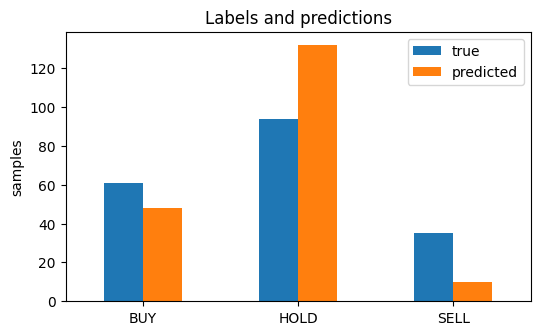

In [4]:
dist = pd.DataFrame(
    {
        "true": df["label"].value_counts().reindex(CLASSES).fillna(0).astype(int),
        "predicted": df["direction"].value_counts().reindex(CLASSES).fillna(0).astype(int),
    }
)
dist["true %"] = dist["true"] / n
dist["predicted %"] = dist["predicted"] / n
display(dist)

dist[["true", "predicted"]].plot.bar(rot=0, figsize=(6, 3.5), title="Labels and predictions")
plt.ylabel("samples")
plt.show()

## 4. Confusion matrix, precision and recall

Rows are the true label, columns the prediction. The "base rate" column is the share
of the class among the labels: if precision equals the base rate, the model saying
that class carries no information.

direction,BUY,HOLD,SELL
label,,,
BUY,15,41,5
HOLD,20,70,4
SELL,13,21,1


,precision,recall,base rate,predictions
BUY,0.312,0.246,0.321,48
HOLD,0.530,0.745,0.495,132
SELL,0.100,0.029,0.184,10


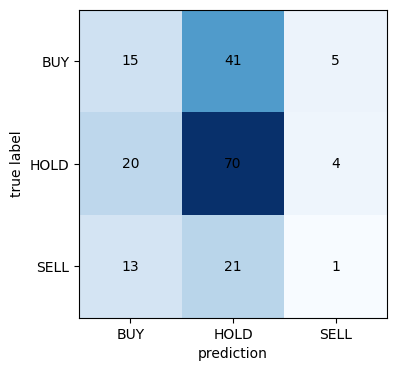

In [5]:
confusion = pd.crosstab(df["label"], df["direction"]).reindex(index=CLASSES, columns=CLASSES, fill_value=0)
display(confusion)

per_class = pd.DataFrame(
    {
        "precision": [confusion.loc[c, c] / confusion[c].sum() if confusion[c].sum() else np.nan for c in CLASSES],
        "recall": [confusion.loc[c, c] / confusion.loc[c].sum() if confusion.loc[c].sum() else np.nan for c in CLASSES],
        "base rate": true_share.values,
        "predictions": confusion.sum(axis=0).values,
    },
    index=CLASSES,
)
display(per_class)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(confusion.values, cmap="Blues")
ax.set_xticks(range(3), CLASSES)
ax.set_yticks(range(3), CLASSES)
ax.set_xlabel("prediction")
ax.set_ylabel("true label")
for i in range(3):
    for j in range(3):
        ax.text(j, i, confusion.values[i, j], ha="center", va="center")
plt.show()

## 5. Confidence calibration

Does higher confidence (the Portfolio Manager's `confidence`) mean higher accuracy?
If accuracy is similar across the bins, confidence carries no information.

In [6]:
bins = [0.5, 0.6, 0.7, 0.8, 0.9, 1.01]
names = ["0.5-0.6", "0.6-0.7", "0.7-0.8", "0.8-0.9", "0.9-1.0"]
df["confidence_bin"] = pd.cut(df["confidence"], bins=bins, labels=names, right=False)
calibration = df.groupby("confidence_bin", observed=False)["correct"].agg(["count", "mean"])
calibration.columns = ["n", "accuracy"]
display(calibration)

print("confidence values:")
display(df["confidence"].value_counts().sort_index().to_frame("n"))

,n,accuracy
confidence_bin,,
0.5-0.6,9,0.667
0.6-0.7,64,0.422
0.7-0.8,64,0.516
0.8-0.9,50,0.400
0.9-1.0,3,0.000


confidence values:


,n
confidence,
0.500,1
0.520,1
0.550,4
0.570,3
0.600,44
0.630,1
0.650,17
0.670,1
0.680,1


## 6. Returns after the signals

Mean return at the end of the horizon (`ret_end`, in %) by prediction and by true
label. It shows whether BUY/SELL signals actually separate better from worse cases.
`sigma_h` is the barrier width used in the label.

In [7]:
by_pred = (df.groupby("direction")["ret_end"].agg(["count", "mean", "median"]) * [1, 100, 100]).reindex(CLASSES)
by_true = (df.groupby("label")["ret_end"].agg(["count", "mean", "median"]) * [1, 100, 100]).reindex(CLASSES)
print("by prediction (return in %):")
display(by_pred)
print("by true label (return in %):")
display(by_true)
print(f"mean sigma_h: {df['sigma_h'].mean() * 100:.1f}%")

by prediction (return in %):


,count,mean,median
direction,,,
BUY,48,2.862,1.673
HOLD,132,2.390,0.875
SELL,10,11.744,8.246


by true label (return in %):


,count,mean,median
label,,,
BUY,61,17.460,12.619
HOLD,94,-0.136,-0.497
SELL,35,-13.771,-11.834


mean sigma_h: 14.2%


## 7. Breakdown by ticker, quarter and debate

In [8]:
def breakdown(by):
    g = df.groupby(by, observed=True)
    out = pd.DataFrame({"n": g.size(), "accuracy": g["correct"].mean()})
    preds_by = pd.crosstab(df[by], df["direction"]).reindex(columns=CLASSES, fill_value=0)
    return out.join(preds_by)


print("by ticker:")
display(breakdown("ticker"))
print("by quarter (as_of dates):")
display(breakdown("quarter"))
print("by number of debate rounds:")
display(breakdown("rounds_used"))
print("whether the critic agreed:")
display(breakdown("critic_agreed"))

by ticker:


,n,accuracy,BUY,HOLD,SELL
ticker,,,,,
AAPL,19,0.579,7,12,0
CAT,19,0.211,3,15,1
GS,19,0.579,4,14,1
INTC,19,0.526,2,14,3
META,19,0.316,11,8,0
NFLX,19,0.526,0,18,1
NVDA,19,0.526,13,6,0
PLTR,19,0.474,4,15,0
SMCI,19,0.368,3,15,1


by quarter (as_of dates):


,n,accuracy,BUY,HOLD,SELL
quarter,,,,,
2025Q1,20,0.400,4,15,1
2025Q2,30,0.467,7,21,2
2025Q3,30,0.400,7,21,2
2025Q4,30,0.467,10,19,1
2026Q1,30,0.467,3,26,1
2026Q2,30,0.500,14,13,3
2026Q3,20,0.450,3,17,0


by number of debate rounds:


,n,accuracy,BUY,HOLD,SELL
rounds_used,,,,,
1,67,0.463,28,39,0
2,39,0.436,11,27,1
3,84,0.452,9,66,9


whether the critic agreed:


,n,accuracy,BUY,HOLD,SELL
critic_agreed,,,,,
False,64,0.469,3,53,8
True,126,0.444,45,79,2
